Convoluted audio saved as 'output_convoluted.wav'.


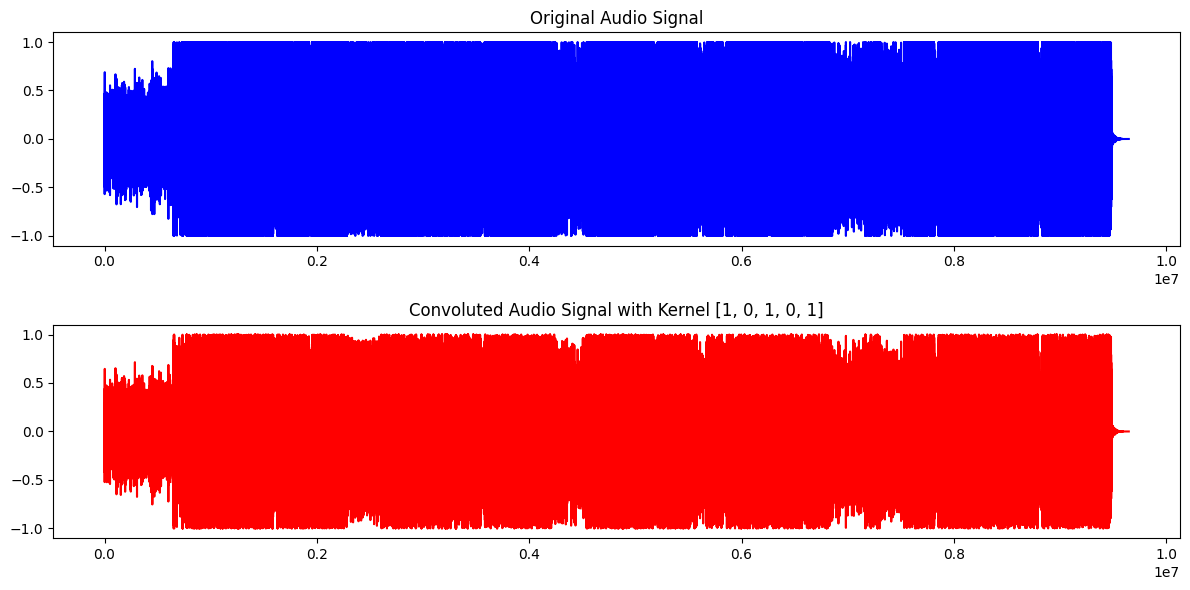

In [6]:
from pydub import AudioSegment
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve


# Load MP3 file
audio = AudioSegment.from_file("Boom Shaka - Krsna.mp3", format="mp3")

# Convert to mono and extract raw samples
audio = audio.set_channels(1)
samples = np.array(audio.get_array_of_samples()).astype(np.float32)

# Define convolution kernel
kernel = np.array([1, 1, 1, 1, 1], dtype=np.float32)/5

# Perform convolution
convoluted = convolve(samples, kernel, mode='same')

# Normalize to int16 range for saving
convoluted = convoluted / np.max(np.abs(convoluted))  # Normalize to [-1, 1]
convoluted_int16 = (convoluted * 32767).astype(np.int16)  # Scale to int16

# Save as WAV using PyDub
convoluted_audio = AudioSegment(
    convoluted_int16.tobytes(),
    frame_rate=audio.frame_rate,
    sample_width=2,  # 16-bit samples = 2 bytes
    channels=1
)

# Export to file
convoluted_audio.export("output_convoluted.wav", format="wav")
print("Convoluted audio saved as 'output_convoluted.wav'.")

# Plot original and convoluted signals (optional)
samples_norm = samples / np.max(np.abs(samples))
convoluted_norm = convoluted

plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(samples_norm, color='blue')
plt.title("Original Audio Signal")

plt.subplot(2, 1, 2)
plt.plot(convoluted_norm, color='red')
plt.title("Convoluted Audio Signal with Kernel [1, 0, 1, 0, 1]")

plt.tight_layout()
plt.show()

In [10]:
import os

print(os.listdir(r"D:\DSIP 2026\Experiment_2\Open_ended_2"))

['035_open_ended_2.ipynb', 'Boom Shaka - Krsna.mp3']


In [14]:
import os

print(os.path.isfile("Boom Shaka - Krsna.mp3"))

True


In [2]:
import shutil

print(shutil.which("ffmpeg"))

None


In [4]:

import os
import shutil

ffmpeg_bin = os.path.join(
    os.environ["LOCALAPPDATA"],
    "Microsoft",
    "WinGet",
    "Packages",
    "Gyan.FFmpeg.Shared_Microsoft.Winget.Source_8wekyb3d8bbwe",
    "ffmpeg-9.0.2-full_build-shared",
    "bin"
)

os.environ["PATH"] = ffmpeg_bin + os.pathsep + os.environ["PATH"]

print("FFmpeg:", shutil.which("ffmpeg"))
print("FFprobe:", shutil.which("ffprobe"))


FFmpeg: C:\Users\rajdeepsinh jadeja\AppData\Local\Microsoft\WinGet\Packages\Gyan.FFmpeg.Shared_Microsoft.Winget.Source_8wekyb3d8bbwe\ffmpeg-9.0.2-full_build-shared\bin\ffmpeg.EXE
FFprobe: C:\Users\rajdeepsinh jadeja\AppData\Local\Microsoft\WinGet\Packages\Gyan.FFmpeg.Shared_Microsoft.Winget.Source_8wekyb3d8bbwe\ffmpeg-9.0.2-full_build-shared\bin\ffprobe.EXE


In [5]:

from pydub import AudioSegment
import os

file_path = os.path.join(
    os.getcwd(),
    "Boom Shaka - Krsna.mp3"
)

audio = AudioSegment.from_file(file_path, format="mp3")

print("Audio loaded successfully!")
print("Duration:", len(audio) / 1000, "seconds")


Audio loaded successfully!
Duration: 218.769 seconds
